In [2]:
import pandas as pd
import matplotlib.ticker as mticker # Needed for y-axis formatting
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df = pd.read_csv('/Users/go202/Desktop/EQUATE/huggingface_longitudinal_work/wayback_work/huggingface_languages_timeseries.csv')

/var/folders/hw/3z11r39j0gd4kgzxbjj6v8z80000gp/T/ipykernel_931/2588941549.py:50: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  a.legend(loc='upper left')


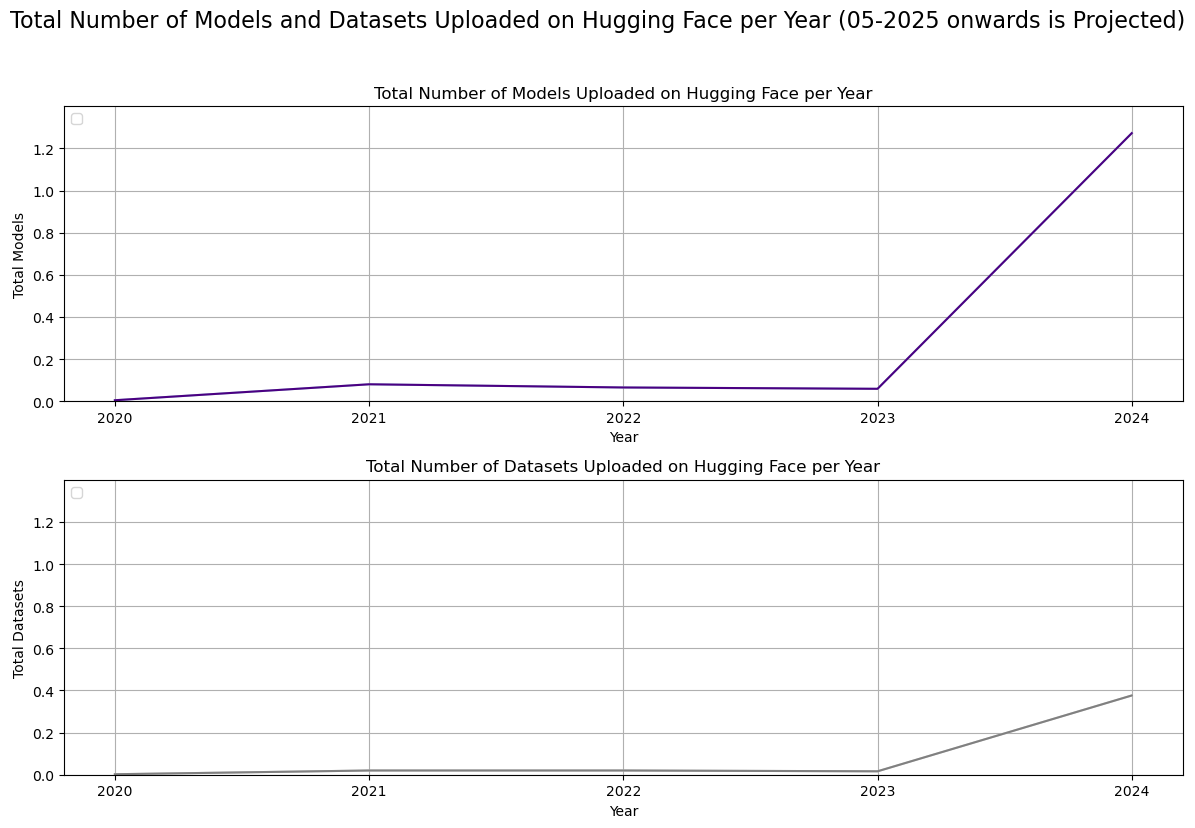

In [5]:
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year

# Step 1: Get latest snapshot per year
latest_dates = df.groupby("year")["date"].max().reset_index()
latest_snapshots = pd.merge(df, latest_dates, on=["year", "date"])

# Step 2: Sum for years before 2025
yearly_totals = latest_snapshots.groupby("year")[["models", "datasets"]].sum().reset_index()
yearly_totals = yearly_totals[yearly_totals["year"] < 2025]

# Initialize extra columns to 0 for existing years before concatenating
yearly_totals["extra_models"] = 0
yearly_totals["extra_datasets"] = 0
yearly_totals = pd.concat([yearly_totals], ignore_index=True)
yearly_totals = yearly_totals[yearly_totals["year"] < 2025] 

# Removed sharex=True to allow independent x-axis labels
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# Models
# Plotting projected line (actual + extra)
ax[0].plot(yearly_totals["year"], yearly_totals["models"],color="lightblue")
# Filling between actual and projected

# Plotting actual line
ax[0].plot(yearly_totals["year"], yearly_totals["models"], color="indigo")
ax[0].set_ylabel("Total Models")
ax[0].set_title("Total Number of Models Uploaded on Hugging Face per Year")
ax[0].set_xlabel("Year")

# Datasets
# Plotting projected line (actual + extra)
ax[1].plot(yearly_totals["year"], yearly_totals["datasets"], color="lightgray")
# Filling between actual and projected
# Plotting actual line
ax[1].plot(yearly_totals["year"], yearly_totals["datasets"], color="gray")
ax[1].set_ylabel("Total Datasets")
ax[1].set_title("Total Number of Datasets Uploaded on Hugging Face per Year")
ax[1].set_xlabel("Year")


# Determine global max for y-axis consistency
max_models = (yearly_totals["models"]).max()
max_datasets = (yearly_totals["datasets"]).max()
global_max_y = max(max_models, max_datasets) * 1.1

# Common settings
for a in ax:
    a.legend(loc='upper left')
    a.grid(True)
    a.set_ylim(0, global_max_y)

    # Format y-axis to display in 1e6 format
    formatter = mticker.FormatStrFormatter('%.1f') # Displays 1.0, 1.2, etc.
    a.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x/1e6:.1f}' if x != 0 else '0.0')) # Divide by 1e6
    a.set_yticks(np.arange(0, global_max_y, global_max_y / 7)) # Adjust tick density if needed

    # Set x-axis tick formatter to display integers without .0
    x_formatter = mticker.FormatStrFormatter('%d')
    a.xaxis.set_major_formatter(x_formatter)
    a.xaxis.set_major_locator(mticker.FixedLocator(yearly_totals["year"].unique()))


fig.suptitle("Total Number of Models and Datasets Uploaded on Hugging Face per Year (05-2025 onwards is Projected)", fontsize=16, y=1.03)

plt.tight_layout()
plt.savefig("develop_over_time_no_proj.pdf")
plt.show()

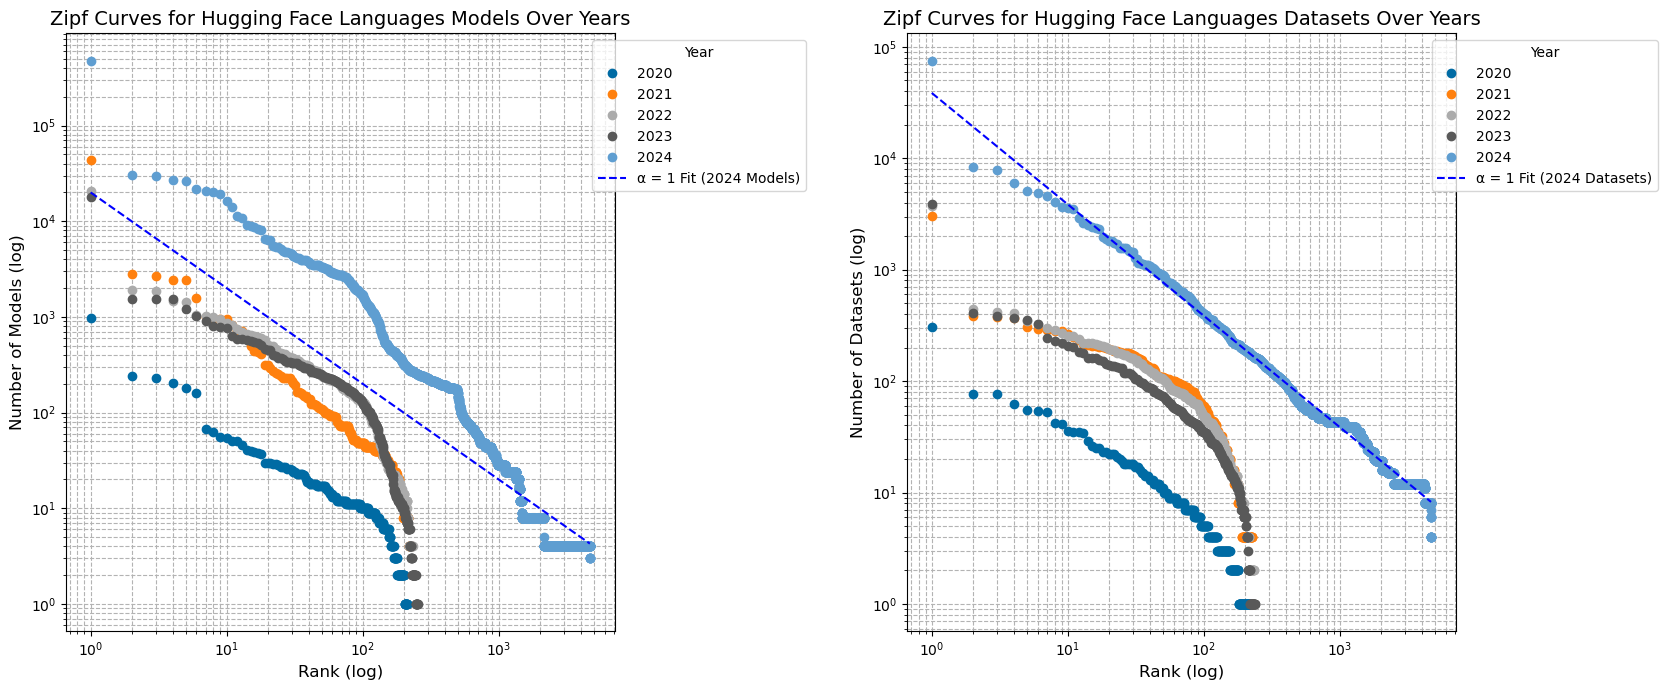

In [7]:
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year

# Step 1: Get latest snapshot date per year
latest_dates = df.groupby("year")["date"].max().reset_index()

# Step 2: Merge to get all rows from latest snapshot of each year
latest_snapshots = pd.merge(df, latest_dates, on=["year", "date"])

# Step 3: Remove 2025 as it's not a complete year
latest_snapshots = latest_snapshots[latest_snapshots["year"] < 2025]

# Step 4: Apply a colorblind-friendly style and prepare the figure with two subplots
plt.style.use('tableau-colorblind10')
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=False) # Two columns, wider figure

# Removed the explicit year_colors dictionary, Matplotlib will use the style's default cycle

# --- Plot 1: Models ---
ax1 = axes[0] # First subplot for Models
for year in sorted(latest_snapshots["year"].unique()):
    data = latest_snapshots[latest_snapshots["year"] == year]
    lang_model_counts = data.groupby("code")["models"].sum().sort_values(ascending=False)

    ranks = np.arange(1, len(lang_model_counts) + 1)
    frequencies = lang_model_counts.values

    valid_indices = (frequencies > 0) & (ranks > 0)
    ranks_filtered = ranks[valid_indices]
    frequencies_filtered = frequencies[valid_indices]

    # Removed the 'color' parameter to use default style colors
    ax1.plot(ranks_filtered, frequencies_filtered, marker='o', linestyle='',
             label=f"{year}")

    # Add the Alpha = 1 Line specifically for the 2024 data (Models)
    if year == 2024 and len(ranks_filtered) >= 2:
        log_ranks_for_fit = np.log(ranks_filtered)
        log_frequencies_for_fit = np.log(frequencies_filtered)

        m_alpha1 = -1.0
        c_alpha1 = np.mean(log_frequencies_for_fit - m_alpha1 * log_ranks_for_fit)

        fit_ranks_range = np.array([ranks_filtered.min(), ranks_filtered.max()])
        fit_log_ranks_range = np.log(fit_ranks_range)
        fit_frequencies_alpha1 = np.exp(m_alpha1 * fit_log_ranks_range + c_alpha1)

        ax1.plot(fit_ranks_range, fit_frequencies_alpha1, color='blue', linestyle='--', linewidth=1.5,
                 label=f"α = 1 Fit (2024 Models)")

ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_title("Zipf Curves for Hugging Face Languages Models Over Years", fontsize=14)
ax1.set_xlabel("Rank (log)", fontsize=12)
ax1.set_ylabel("Number of Models (log)", fontsize=12) # Adjusted label back to "Models (log)"
ax1.legend(title="Year", loc='upper right', bbox_to_anchor=(1.36, 1)) # Moved legend outside for clarity
ax1.grid(True, which="both", ls="--", c='0.7')

# --- Plot 2: Datasets ---
ax2 = axes[1] # Second subplot for Datasets
for year in sorted(latest_snapshots["year"].unique()):
    data = latest_snapshots[latest_snapshots["year"] == year]
    lang_dataset_counts = data.groupby("code")["datasets"].sum().sort_values(ascending=False)

    ranks = np.arange(1, len(lang_dataset_counts) + 1)
    frequencies = lang_dataset_counts.values

    valid_indices = (frequencies > 0) & (ranks > 0)
    ranks_filtered = ranks[valid_indices]
    frequencies_filtered = frequencies[valid_indices]

    # Removed the 'color' parameter to use default style colors
    ax2.plot(ranks_filtered, frequencies_filtered, marker='o', linestyle='',
             label=f"{year}")

    # Add the Alpha = 1 Line specifically for the 2024 data (Datasets)
    if year == 2024 and len(ranks_filtered) >= 2:
        log_ranks_for_fit = np.log(ranks_filtered)
        log_frequencies_for_fit = np.log(frequencies_filtered)

        m_alpha1 = -1.0
        c_alpha1 = np.mean(log_frequencies_for_fit - m_alpha1 * log_ranks_for_fit)

        fit_ranks_range = np.array([ranks_filtered.min(), ranks_filtered.max()])
        fit_log_ranks_range = np.log(fit_ranks_range)
        fit_frequencies_alpha1 = np.exp(m_alpha1 * fit_log_ranks_range + c_alpha1)

        ax2.plot(fit_ranks_range, fit_frequencies_alpha1, color='blue', linestyle='--', linewidth=1.5,
                 label=f"α = 1 Fit (2024 Datasets)")

ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_title("Zipf Curves for Hugging Face Languages Datasets Over Years", fontsize=14)
ax2.set_xlabel("Rank (log)", fontsize=12)
ax2.set_ylabel("Number of Datasets (log)", fontsize=12)
ax2.legend(title="Year", loc='upper right', bbox_to_anchor=(1.38, 1)) # Moved legend outside for clarity
ax2.grid(True, which="both", ls="--", c='0.7')

plt.tight_layout(rect=[0, 0, 0.95, 1]) # Adjust layout to make space for the legends
plt.savefig('combined_zipfs_models_datasets_original_colors.pdf') # New filename
plt.show()

/var/folders/hw/3z11r39j0gd4kgzxbjj6v8z80000gp/T/ipykernel_931/4257369150.py:90: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color = plt.cm.get_cmap('Dark2')(i / (num_languages_to_annotate - 1))


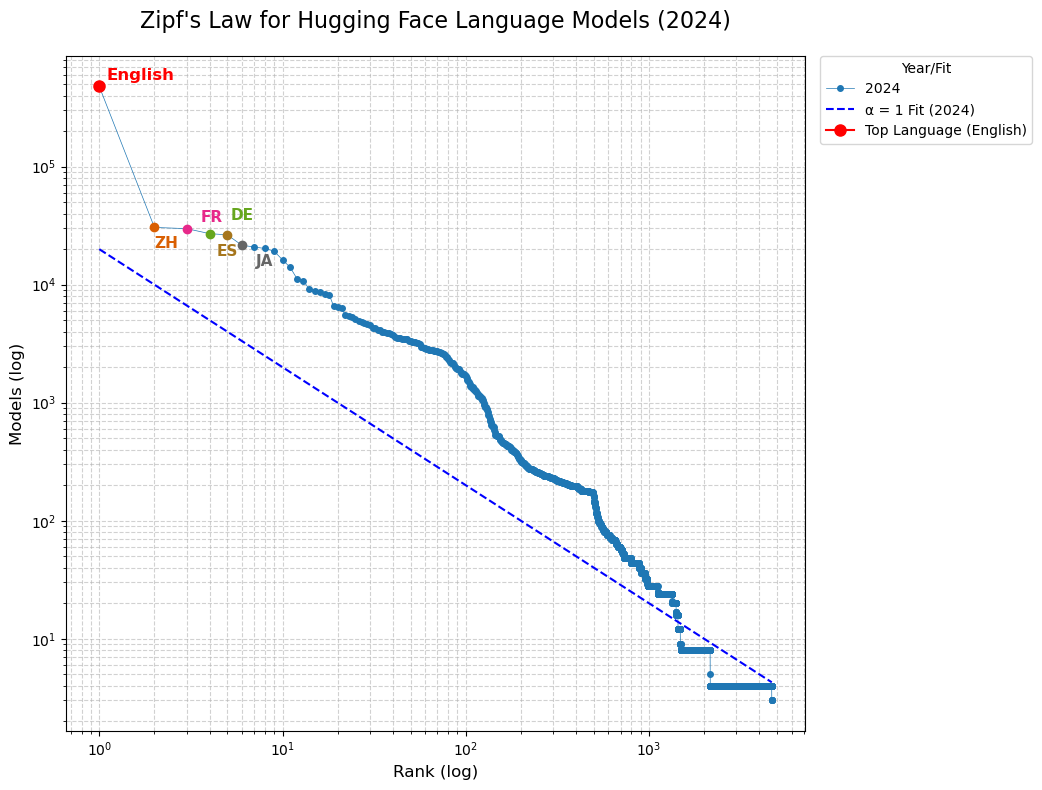

In [8]:
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year

# Step 1: Get latest snapshot date per year
latest_dates = df.groupby("year")["date"].max().reset_index()

# Step 2: Merge to get all rows from latest snapshot of each year
latest_snapshots = pd.merge(df, latest_dates, on=["year", "date"])

# Step 3: Filter to keep only the 2024 data
latest_snapshots = latest_snapshots[latest_snapshots["year"] == 2024]

# Step 4: Apply a colorblind-friendly style and prepare a single plot
plt.style.use('tableau-colorblind10')
fig, ax = plt.subplots(1, 1, figsize=(12, 8)) # Slightly larger figure for better spacing

# Step 5: Plot Zipf curve for 2024 and its Alpha = 1 Line
year = 2024
data = latest_snapshots[latest_snapshots["year"] == year]
lang_model_counts = data.groupby("code")["models"].sum().sort_values(ascending=False)

# Ensure ranks are based on the sorted unique languages
ranks = np.arange(1, len(lang_model_counts) + 1)
frequencies = lang_model_counts.values

# Filter out ranks or frequencies that are zero or negative for log plot
valid_indices = (frequencies > 0) & (ranks > 0)
ranks_filtered = ranks[valid_indices]
frequencies_filtered = frequencies[valid_indices]
lang_codes_filtered = lang_model_counts.index[valid_indices] # Keep track of corresponding language codes

# Plotting with markers and a solid line for better distinction
ax.plot(ranks_filtered, frequencies_filtered, marker='o', linestyle='-', markersize=4,
        label=f"{year}", color='#1f77b4', linewidth=0.5) # Using a default tableau color

# Add the Alpha = 1 Line specifically for the 2024 data
if len(ranks_filtered) >= 2:
    # Use only valid, non-zero ranks and frequencies for log fit
    log_ranks_for_fit = np.log(ranks_filtered)
    log_frequencies_for_fit = np.log(frequencies_filtered)

    m_alpha1 = -1.0
    # Calculate intercept based on 2024 data
    c_alpha1 = np.mean(log_frequencies_for_fit - m_alpha1 * log_ranks_for_fit)

    # Generate points for the alpha=1 fitted line
    fit_ranks_range = np.array([ranks_filtered.min(), ranks_filtered.max()])
    fit_log_ranks_range = np.log(fit_ranks_range)
    fit_frequencies_alpha1 = np.exp(m_alpha1 * fit_log_ranks_range + c_alpha1)

    ax.plot(fit_ranks_range, fit_frequencies_alpha1, color='blue', linestyle='--', linewidth=1.5,
            label=f"α = 1 Fit (2024)")

# --- Language Annotation (Bold, Larger, and Adjusted Positions) ---
num_languages_to_annotate = 6 # English + top 5 others
annotated_langs = []
# Adjusted offsets for the top 6 languages (including English)
# The indices in this list correspond to the order AFTER English in lang_model_counts
# e.g., if ZH is 2nd overall, it gets annotation_offsets[1]
annotation_offsets = {
    # English has its own custom offset below
    'zh': (0, -15),  # Chinese (assuming it's the second most frequent)
    'fr': (10, 5),   # French
    'es': (-8, -15), # Spanish
    'de': (15, 10),  # German (Adjusted: more right, slightly up)
    'ja': (10, -15), # Japanese (Adjusted: more right, slightly down)
    'ko': (10, 5)    # Korean (example for next language if needed)
}


for i, (lang_code, freq) in enumerate(lang_model_counts.items()):
    if i >= num_languages_to_annotate: # Only annotate the top N
        break

    rank = i + 1 # Rank is 1-based index
    
    # Check if this language is in the filtered valid_indices
    if lang_code not in lang_codes_filtered.values or freq <= 0:
        continue # Skip if not a valid point for log plot

    # Special handling for English (Rank 1)
    if rank == 1:
        color = 'red'
        label = "Top Language (English)" if i == 0 else "_nolegend_"
        ax.plot(rank, freq, marker='o', markersize=8, color=color, label=label, zorder=5)
        ax.annotate("English", (rank, freq), textcoords="offset points", xytext=(5, 5), ha='left',
                    color=color, fontsize=12, fontweight='bold')
    else:
        # Use a distinct color for other top languages from the tableau palette
        color = plt.cm.get_cmap('Dark2')(i / (num_languages_to_annotate - 1))
        
        ax.plot(rank, freq, marker='o', markersize=6, color=color)
        
        # Use the specific offset for this language code, if defined, otherwise a default
        offset_x, offset_y = annotation_offsets.get(lang_code, (10, 5)) # Default to (10,5) if not in map
        
        ax.annotate(lang_code.upper(), (rank, freq),
                    textcoords="offset points", xytext=(offset_x, offset_y), ha='left',
                    fontsize=11, color=color, fontweight='bold')
    
    annotated_langs.append(lang_code)

# --- General Plot Settings ---
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Zipf's Law for Hugging Face Language Models (2024)", fontsize=16, pad=20)
ax.set_xlabel("Rank (log)", fontsize=12)
ax.set_ylabel("Models (log)", fontsize=12)

# Adjust legend position to be outside the plot
ax.legend(title="Year/Fit", loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0.)

ax.grid(True, which="both", ls="--", c='0.7', alpha=0.6)

plt.tight_layout(rect=[0, 0, 0.88, 1]) # Adjust layout to make space for the legend on the right
#plt.savefig('zipfs_law_language_models_2024_final.pdf', bbox_inches='tight')
plt.show()